# Lab 2 - EDA và làm sạch BigMart
Nguồn: https://www.kaggle.com/datasets/yasserh/bigmartsalesdataset

**Bài toán:** dự đoán `Item_Outlet_Sales` của sản phẩm tại cửa hàng từ thuộc tính sản phẩm và cửa hàng. Đây là giá trị doanh số, không gọi là số lượng sản phẩm bán ra. Dataset không xác định rõ đơn vị tiền trong file.
Không có ngày bán: chưa thể dùng dataset này để minh họa dự báo doanh số theo ngày/tuần.

Giai đoạn hiện tại: đọc, khám phá, chuẩn hóa dữ liệu và ghi lại chất lượng. Chưa train model hoặc tuning.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Datasets/data_raw/bigmart.csv").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook bên trong thư mục GR_05_Lab_2.")
    ROOT = ROOT.parent
output = ROOT / "outputs"
processed = ROOT / "Datasets/data_processed"
figures = output / "figures"
for folder in [output, processed, figures]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"


## 1. Đọc dữ liệu gốc
Một dòng biểu diễn một sản phẩm tại một cửa hàng. Giữ mã định danh ở dạng chuỗi.
`source_row` trong bản xử lý là chỉ mục bản ghi từ 0 để tra lại dữ liệu gốc, không phải đặc trưng của mô hình.


In [2]:
raw = pd.read_csv(ROOT / "Datasets/data_raw/bigmart.csv",
                  dtype={"Item_Identifier": "string", "Outlet_Identifier": "string"})
print("Số dòng, số cột:", raw.shape)
print("Sản phẩm:", raw["Item_Identifier"].nunique())
print("Cửa hàng:", raw["Outlet_Identifier"].nunique())
print("Trùng toàn bộ dòng:", raw.duplicated().sum())
print("Trùng cặp sản phẩm/cửa hàng:", raw.duplicated(["Item_Identifier", "Outlet_Identifier"]).sum())
print("Kiểu dữ liệu:")
print(raw.dtypes.to_string())
print("Các giá trị Item_Fat_Content:")
print(raw["Item_Fat_Content"].value_counts().to_string())
raw.head()


Số dòng, số cột: (8523, 12)
Sản phẩm: 1559
Cửa hàng: 10
Trùng toàn bộ dòng: 0
Trùng cặp sản phẩm/cửa hàng: 0
Kiểu dữ liệu:
Item_Identifier               string
Item_Weight                  float64
Item_Fat_Content                 str
Item_Visibility              float64
Item_Type                        str
Item_MRP                     float64
Outlet_Identifier             string
Outlet_Establishment_Year      int64
Outlet_Size                      str
Outlet_Location_Type             str
Outlet_Type                      str
Item_Outlet_Sales            float64
Các giá trị Item_Fat_Content:
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
  Item_Identifier  Item_Weight  ...        Outlet_Type  Item_Outlet_Sales
0           FDA15         9.30  ...  Supermarket Type1          3735.1380
1           DRC01         5.92  ...  Supermarket Type2           443.4228
2           FDN15        17.50  ...  Supermarket Type1          2097.2700
3         

## 2. Kiểm tra thiếu, mục tiêu và giá trị bất thường
Không tự xóa số 0 ở Item_Visibility: 0 có thể là chưa đo/không trưng bày, chưa có bằng chứng chắc chắn là lỗi.
Chỉ đánh dấu để phân tích sau. Giữ các doanh số lớn hợp lệ; không cắt ngoại lệ theo percentile.


In [3]:
missing_raw = pd.DataFrame({"Số thiếu": raw.isna().sum(),
                            "Tỷ lệ thiếu (%)": raw.isna().mean()*100})
print(missing_raw.round(2).to_string())
target = raw["Item_Outlet_Sales"]
print("Mục tiêu thiếu:", target.isna().sum())
print("Mục tiêu bằng 0:", target.eq(0).sum())
print("Mục tiêu âm:", target.lt(0).sum())
print("Nhỏ nhất/lớn nhất:", target.min(), target.max())
print("Item_Visibility bằng 0:", raw["Item_Visibility"].eq(0).sum())
print(raw.select_dtypes(include="number").describe().round(2).to_string())
missing_raw.to_csv(output / "missing_raw.csv", encoding="utf-8-sig", index_label="Cột")


                           Số thiếu  Tỷ lệ thiếu (%)
Item_Identifier                   0             0.00
Item_Weight                    1463            17.17
Item_Fat_Content                  0             0.00
Item_Visibility                   0             0.00
Item_Type                         0             0.00
Item_MRP                          0             0.00
Outlet_Identifier                 0             0.00
Outlet_Establishment_Year         0             0.00
Outlet_Size                    2410            28.28
Outlet_Location_Type              0             0.00
Outlet_Type                       0             0.00
Item_Outlet_Sales                 0             0.00
Mục tiêu thiếu: 0
Mục tiêu bằng 0: 0
Mục tiêu âm: 0
Nhỏ nhất/lớn nhất: 33.29 13086.9648
Item_Visibility bằng 0: 526
       Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year  Item_Outlet_Sales
count      7060.00          8523.00   8523.00                    8523.00            8523.00
mean       

## 3. Làm sạch định dạng và chuẩn hóa nhãn
- Bỏ khoảng trắng thừa trong các cột dạng chuỗi; chuỗi rỗng được xem là thiếu.
- Chuẩn hóa LF, low fat thành Low Fat; reg thành Regular. Không nhập nhãn chưa rõ vào một nhóm tùy ý.
- Kiểm tra các trường bắt buộc và phạm vi giá trị trước khi lưu.
- Cột Item_Weight và Outlet_Size còn thiếu được giữ lại. Ở bước mô hình, chia train/validation/test trước rồi học median/mode chỉ từ train. Không tính median/mode trên toàn bộ dữ liệu.


In [4]:
clean = raw.copy()
clean.insert(0, "source_row", raw.index)
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    clean[column] = clean[column].astype("string").str.strip()
    clean.loc[clean[column] == "", column] = pd.NA

fat_before = clean["Item_Fat_Content"].copy()
fat_names = {"low fat": "Low Fat", "lowfat": "Low Fat", "lf": "Low Fat",
             "regular": "Regular", "reg": "Regular"}
clean["Item_Fat_Content"] = clean["Item_Fat_Content"].str.lower().map(fat_names)
if clean["Item_Fat_Content"].isna().any():
    raise ValueError("Có nhãn hàm lượng chất béo chưa xác định; cần kiểm tra trước khi tiếp tục.")
changed_fat = int(fat_before.ne(clean["Item_Fat_Content"]).sum())

# Không gộp theo mã sản phẩm vì một sản phẩm có thể xuất hiện tại nhiều cửa hàng.
duplicate_rows = raw.duplicated(keep="first")
clean = clean.loc[~duplicate_rows].copy()
clean["Item_Weight_Missing"] = clean["Item_Weight"].isna().astype(int)
clean["Outlet_Size_Missing"] = clean["Outlet_Size"].isna().astype(int)
clean["Item_Visibility_Zero"] = clean["Item_Visibility"].eq(0).astype(int)
print("Số nhãn Item_Fat_Content được chuẩn hóa:", changed_fat)
print(clean["Item_Fat_Content"].value_counts().to_string())
print("Số dòng sau chuẩn hóa:", len(clean))


Số nhãn Item_Fat_Content được chuẩn hóa: 545
Item_Fat_Content
Low Fat    5517
Regular    3006
Số dòng sau chuẩn hóa: 8523


## 4. Kiểm chứng và xuất dữ liệu
`bigmart_clean.csv` đã sạch định dạng nhưng cố ý giữ ô thiếu để tránh rò rỉ khi điền thiếu.
Các cờ 0/1 mô tả chất lượng; chưa quyết định đưa chúng vào mô hình.
MAPE có thể tính trên mục tiêu dương hiện tại; mục tiêu nhỏ vẫn có thể làm MAPE nhạy với sai số.


In [5]:
required = ["Item_Identifier", "Outlet_Identifier", "Item_Outlet_Sales", "Item_MRP", "Item_Type"]
assert clean[required].notna().all().all()
assert clean["Item_Outlet_Sales"].gt(0).all()
assert clean["Item_MRP"].gt(0).all()
assert clean["Item_Weight"].dropna().gt(0).all()
assert clean["Item_Visibility"].between(0, 1).all()
assert clean["source_row"].is_unique
assert not clean.duplicated(["Item_Identifier", "Outlet_Identifier"]).any()
assert set(clean["Item_Fat_Content"]) == {"Low Fat", "Regular"}

clean.to_csv(processed / "bigmart_clean.csv", index=False, encoding="utf-8-sig")
missing = pd.DataFrame({"Trước": raw.isna().sum(), "Sau chuẩn hóa": clean[raw.columns].isna().sum()})
missing.to_csv(output / "missing_before_after.csv", encoding="utf-8-sig", index_label="Cột")
summary = pd.Series({"raw_rows": len(raw), "raw_columns": raw.shape[1],
                     "clean_rows": len(clean), "duplicates_removed": int(duplicate_rows.sum()),
                     "products": clean["Item_Identifier"].nunique(),
                     "outlets": clean["Outlet_Identifier"].nunique(),
                     "fat_labels_normalized": changed_fat,
                     "missing_item_weight": int(clean["Item_Weight"].isna().sum()),
                     "missing_outlet_size": int(clean["Outlet_Size"].isna().sum()),
                     "zero_visibility": int(clean["Item_Visibility"].eq(0).sum()),
                     "zero_target": int(clean["Item_Outlet_Sales"].eq(0).sum()),
                     "negative_target": int(clean["Item_Outlet_Sales"].lt(0).sum())}, name="value")
summary.to_csv(output / "cleaning_summary.csv", index_label="metric")
print(summary.to_string())
print("Đã lưu dữ liệu và thống kê. Chưa điền thiếu hoặc train model.")


raw_rows                 8523
raw_columns                12
clean_rows               8523
duplicates_removed          0
products                 1559
outlets                    10
fat_labels_normalized     545
missing_item_weight      1463
missing_outlet_size      2410
zero_visibility           526
zero_target                 0
negative_target             0
Đã lưu dữ liệu và thống kê. Chưa điền thiếu hoặc train model.


## 5. Biểu đồ khám phá ban đầu
Biểu đồ thể hiện phân bố doanh số, dữ liệu thiếu, doanh số theo loại cửa hàng và mối liên hệ giá niêm yết-doanh số.
Đây là mô tả, không chứng minh quan hệ nhân quả. Chưa dùng biểu đồ để chọn mô hình hoặc tối ưu trên test.


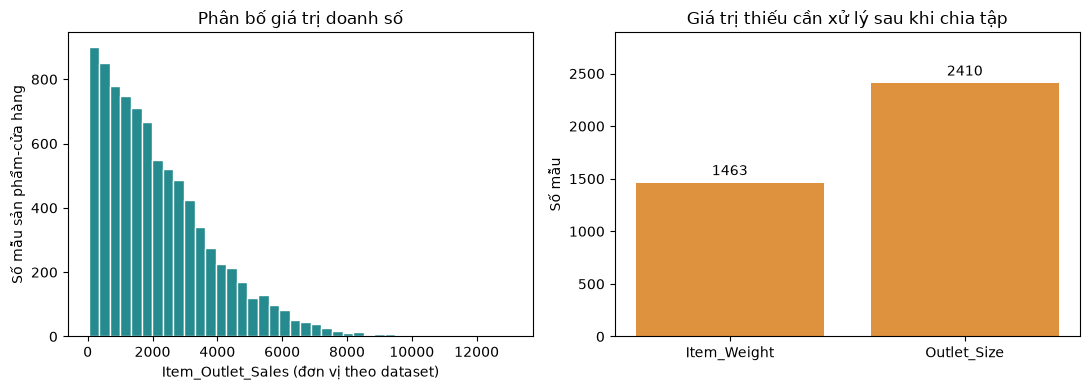

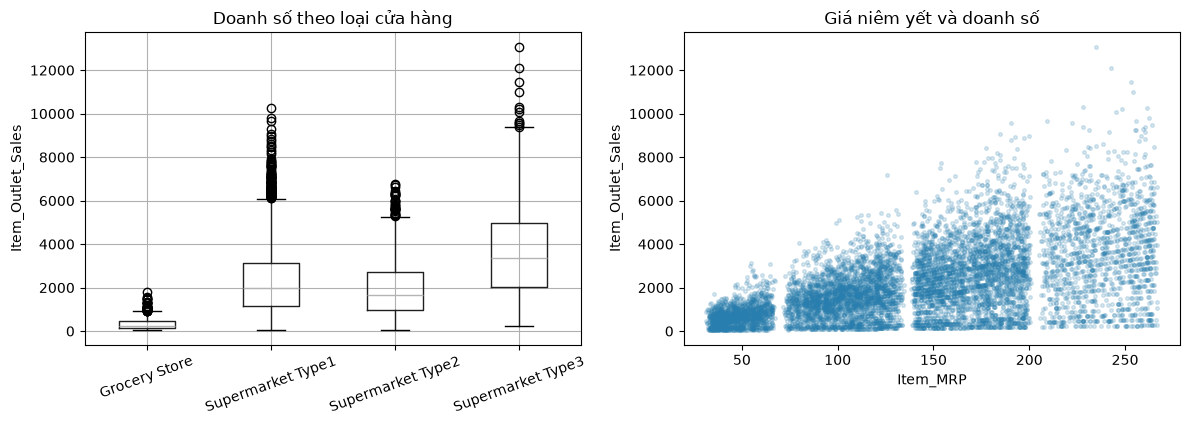

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(clean["Item_Outlet_Sales"], bins=40, color="#258b8e", edgecolor="white")
axes[0].set_title("Phân bố giá trị doanh số")
axes[0].set_xlabel("Item_Outlet_Sales (đơn vị theo dataset)")
axes[0].set_ylabel("Số mẫu sản phẩm-cửa hàng")
missing_nonzero = missing_raw.loc[missing_raw["Số thiếu"] > 0, "Số thiếu"]
bars = axes[1].bar(missing_nonzero.index, missing_nonzero.values, color="#df923e")
axes[1].bar_label(bars, padding=3)
axes[1].set_title("Giá trị thiếu cần xử lý sau khi chia tập")
axes[1].set_ylabel("Số mẫu")
axes[1].set_ylim(0, max(missing_nonzero.values)*1.2)
fig.tight_layout()
fig.savefig(figures / "bigmart_distribution_missing.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
clean.boxplot(column="Item_Outlet_Sales", by="Outlet_Type", ax=axes[0], rot=20)
axes[0].set_title("Doanh số theo loại cửa hàng")
axes[0].set_xlabel("")
axes[0].set_ylabel("Item_Outlet_Sales")
axes[1].scatter(clean["Item_MRP"], clean["Item_Outlet_Sales"], s=7, alpha=0.18, color="#287eae")
axes[1].set_title("Giá niêm yết và doanh số")
axes[1].set_xlabel("Item_MRP")
axes[1].set_ylabel("Item_Outlet_Sales")
fig.suptitle("")
fig.tight_layout()
fig.savefig(figures / "bigmart_outlet_price.png", dpi=180, bbox_inches="tight")
plt.show()


### Phân bố loại sản phẩm
Đếm số mẫu và mô tả doanh số theo loại sản phẩm. Trung bình ở đây chỉ để EDA, không dùng làm đặc trưng target encoding hoặc chọn cấu hình.


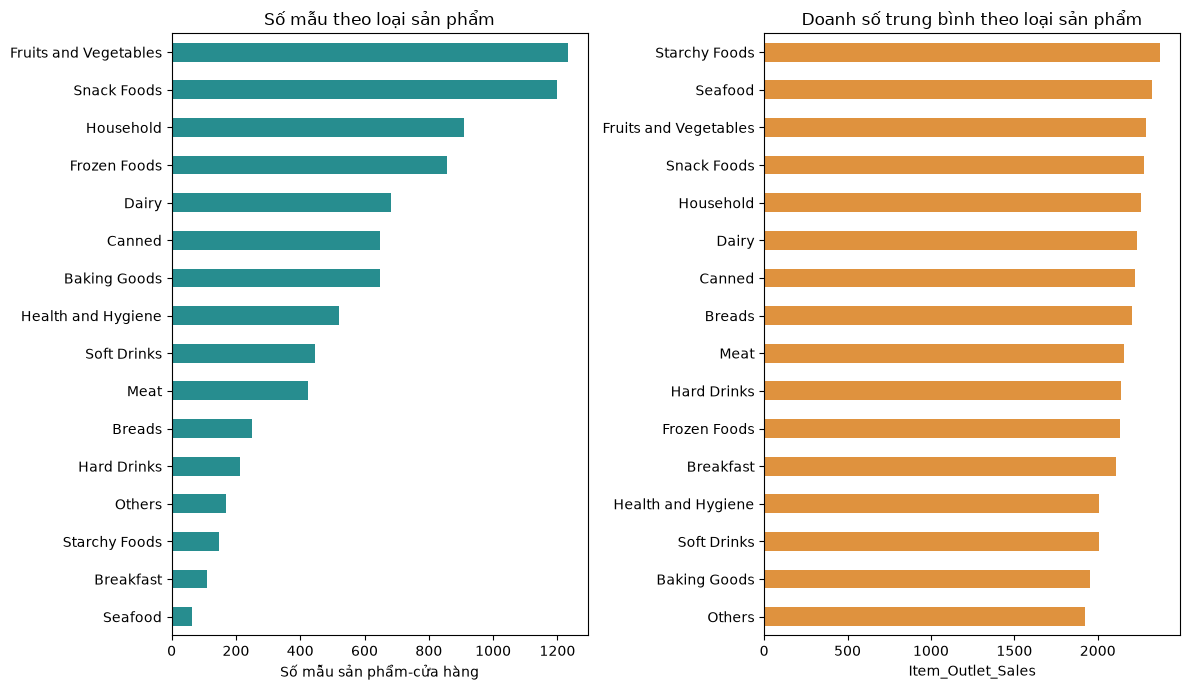

In [7]:
category_profile = clean.groupby("Item_Type")["Item_Outlet_Sales"].agg(["count", "mean", "median"])
category_profile.to_csv(output / "category_profile.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
category_profile["count"].sort_values().plot.barh(ax=axes[0], color="#278d8f")
axes[0].set_title("Số mẫu theo loại sản phẩm")
axes[0].set_xlabel("Số mẫu sản phẩm-cửa hàng")
axes[0].set_ylabel("")
category_profile["mean"].sort_values().plot.barh(ax=axes[1], color="#df923e")
axes[1].set_title("Doanh số trung bình theo loại sản phẩm")
axes[1].set_xlabel("Item_Outlet_Sales")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(figures / "bigmart_category_profiles.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. Nhận xét EDA
- Doanh số lệch phải: nhiều mẫu thấp/trung bình và ít mẫu rất cao. Không tự xóa các giá trị lớn.
- Phân bố doanh số khác nhau giữa các loại cửa hàng; scatter giá và doanh số có xu hướng tăng nhưng không xác nhận nhân quả.
- Không có ngày bán: cách chia dưới đây phục vụ dự đoán sản phẩm-cửa hàng trong cùng phạm vi dữ liệu, không phải dự báo tương lai.
- Cố định đặc trưng và quy trình trước khi train. Không chọn cấu hình bằng kết quả test.


## 7. Chia train/validation/test
Theo bài giảng PDF trang 27: train học tham số, validation chọn cấu hình, test đánh giá cuối.
Tỷ lệ 70/15/15 và seed=42 là cấu hình của nhóm. Mã sản phẩm có thể xuất hiện ở nhiều tập, nhưng không trùng bản ghi; đây không phải đánh giá riêng trên sản phẩm hoàn toàn mới.


            Số mẫu  Tỷ lệ (%)
split                        
train         5966      70.00
validation    1278      14.99
test          1279      15.01


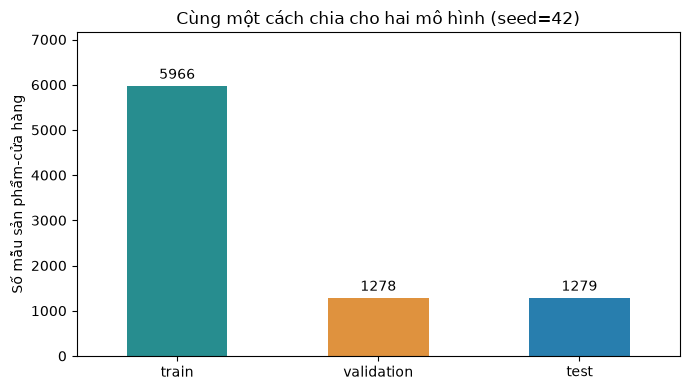

In [8]:
from sklearn.model_selection import train_test_split
import hashlib
import json

# Chia 70%/15%/15%; làm tròn số mẫu theo train_test_split.
train_ids, remaining_ids = train_test_split(
    clean["source_row"].to_numpy(), test_size=0.30, random_state=42)
validation_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.50, random_state=42)
assert set(train_ids).isdisjoint(validation_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)
assert set(train_ids) | set(validation_ids) | set(test_ids) == set(clean["source_row"])

split_indices = pd.concat([
    pd.DataFrame({"source_row": train_ids, "split": "train"}),
    pd.DataFrame({"source_row": validation_ids, "split": "validation"}),
    pd.DataFrame({"source_row": test_ids, "split": "test"}),
], ignore_index=True)
split_indices.to_csv(processed / "split_indices.csv", index=False)
split_summary = split_indices["split"].value_counts().reindex(["train", "validation", "test"]).to_frame("Số mẫu")
split_summary["Tỷ lệ (%)"] = split_summary["Số mẫu"] / len(clean)*100
print(split_summary.round(2).to_string())
split_summary.to_csv(output / "split_summary.csv", encoding="utf-8-sig")
ax = split_summary["Số mẫu"].plot.bar(color=["#278d8f", "#df923e", "#287eae"], rot=0, figsize=(7, 4))
ax.set_title("Cùng một cách chia cho hai mô hình (seed=42)")
ax.set_ylabel("Số mẫu sản phẩm-cửa hàng")
ax.set_xlabel("")
ax.set_ylim(0, split_summary["Số mẫu"].max()*1.2)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.savefig(figures / "split_distribution.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Tiền xử lý chỉ học từ train
Theo nguyên tắc trang 35, mọi thống kê học từ train rồi áp dụng sang tập còn lại.
Median/mode và One-Hot cụ thể là lựa chọn triển khai, bài giảng trang 19 chỉ nêu xử lý thiếu/mã hóa ở mức quy trình.
Giữ các cờ chất lượng; bỏ hai mã định danh và source_row. Không cần StandardScaler cho cách giải OLS bằng least-squares và cây ở bản này.
One-Hot drop nhóm đầu tránh dư thừa trong từng cột; các phụ thuộc giữa nhiều cột vẫn có thể tồn tại, OLS dùng least-squares thay vì nghịch đảo ma trận.


In [9]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np

target_name = "Item_Outlet_Sales"
numeric_columns = ["Item_Weight", "Item_Visibility", "Item_MRP", "Outlet_Establishment_Year",
                   "Item_Weight_Missing", "Outlet_Size_Missing", "Item_Visibility_Zero"]
category_columns = ["Item_Fat_Content", "Item_Type", "Outlet_Size", "Outlet_Location_Type", "Outlet_Type"]
# Không dùng source_row, Item_Identifier, Outlet_Identifier làm đặc trưng.
indexed = clean.set_index("source_row")
train_data = indexed.loc[train_ids].copy()
validation_data = indexed.loc[validation_ids].copy()
test_data = indexed.loc[test_ids].copy()

weight_median = float(train_data["Item_Weight"].median())
size_mode = str(train_data["Outlet_Size"].mode().iloc[0])
print("Trung vị Item_Weight từ train:", weight_median)
print("Mode Outlet_Size từ train:", size_mode)
missing_after = []
for name, frame in [("train", train_data), ("validation", validation_data), ("test", test_data)]:
    before = int(frame[numeric_columns + category_columns].isna().sum().sum())
    frame["Item_Weight"] = frame["Item_Weight"].fillna(weight_median)
    frame["Outlet_Size"] = frame["Outlet_Size"].fillna(size_mode)
    after = int(frame[numeric_columns + category_columns].isna().sum().sum())
    missing_after.append({"Tập": name, "Thiếu trước": before, "Thiếu sau": after})

# Chỉ học danh mục từ train. drop='first' bỏ một nhóm tham chiếu mỗi cột.
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
train_encoded = encoder.fit_transform(train_data[category_columns])
validation_encoded = encoder.transform(validation_data[category_columns])
test_encoded = encoder.transform(test_data[category_columns])
encoded_columns = encoder.get_feature_names_out(category_columns).tolist()
feature_names = numeric_columns + encoded_columns

unknown_categories = {}
for name, frame in [("validation", validation_data), ("test", test_data)]:
    unknown_categories[name] = {}
    for column, categories in zip(category_columns, encoder.categories_):
        unknown_categories[name][column] = int((~frame[column].isin(categories)).sum())
print("Số danh mục ngoài train:", unknown_categories)

for name, frame, encoded in [("train", train_data, train_encoded),
                              ("validation", validation_data, validation_encoded),
                              ("test", test_data, test_encoded)]:
    numbers = frame[numeric_columns].astype(float).to_numpy()
    X = np.column_stack([numbers, encoded])
    assert np.isfinite(X).all()
    assert X.shape == (len(frame), len(feature_names))
    pd.DataFrame(X, index=frame.index, columns=feature_names).to_csv(
        processed / f"X_{name}.csv", index_label="source_row")
    frame[[target_name]].to_csv(processed / f"y_{name}.csv", index_label="source_row")

clean_hash = hashlib.sha256((processed / "bigmart_clean.csv").read_bytes()).hexdigest()
split_hash = hashlib.sha256((processed / "split_indices.csv").read_bytes()).hexdigest()
preprocessing = {
    "seed": 42, "target": target_name, "numeric_columns": numeric_columns,
    "category_columns": category_columns, "feature_names": feature_names,
    "weight_median": weight_median, "size_mode": size_mode,
    "categories": {column: categories.tolist() for column, categories in zip(category_columns, encoder.categories_)},
    "one_hot_drop": "first", "unknown_categories": unknown_categories,
    "unknown_policy": "Bỏ qua: các cột One-Hot của nhóm chưa gặp bằng 0; có thể trùng nhóm tham chiếu.",
    "clean_sha256": clean_hash, "split_sha256": split_hash,
    "n_train": len(train_data), "n_validation": len(validation_data), "n_test": len(test_data),
    "scaling": "Không chuẩn hóa ở bản OLS và cây hiện tại; không huấn luyện gradient descent.",
}
(processed / "preprocessing.json").write_text(json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding="utf-8")
pd.DataFrame(missing_after).to_csv(output / "imputation_summary.csv", index=False, encoding="utf-8-sig")
print(pd.DataFrame(missing_after).to_string(index=False))
print("Số đặc trưng sau mã hóa:", len(feature_names))
print("Đã xuất X/y của ba tập và preprocessing.json.")


Trung vị Item_Weight từ train: 12.65
Mode Outlet_Size từ train: Medium
Số danh mục ngoài train: {'validation': {'Item_Fat_Content': 0, 'Item_Type': 0, 'Outlet_Size': 0, 'Outlet_Location_Type': 0, 'Outlet_Type': 0}, 'test': {'Item_Fat_Content': 0, 'Item_Type': 0, 'Outlet_Size': 0, 'Outlet_Location_Type': 0, 'Outlet_Type': 0}}
       Tập  Thiếu trước  Thiếu sau
     train         2713          0
validation          590          0
      test          570          0
Số đặc trưng sau mã hóa: 30
Đã xuất X/y của ba tập và preprocessing.json.


## 9. Thứ tự chạy tiếp
1. Models/Linear_Regression.ipynb: baseline trung bình train và OLS tự viết.
2. Models/Decision_Tree.ipynb: chọn độ phức tạp bằng validation, đánh giá test và so sánh.
Các notebook model đọc cùng X/y và kiểm tra dấu vết dữ liệu. Khi thay dữ liệu hoặc cách chia, chạy lại toàn bộ theo thứ tự này.
